# Foot Wear Pricing
## Multi-Objective Optimization Analysis

**Student Name:** Carter DiCaprio
**Target Company/Industry:** Foot Locker/ Retail
**Problem:** Balancing profit while still discounting selling shoes to obtain shelf space.
**Objectives:** Profit vs. Space

---


Brief Overview:
Foot-Locker is struggling to turn a profit selling its shoes and needs to keep freeing up space for the new hype shoes. As of the 2nd quarter financial report, Foot Locker's proforma comps has decreased by 3.9%, signalling a decline of the company's profitability and future possibilities. In order to rectify this, this program looks at the decision variabkles of discounting standard and luxury shoes to find out how to turn a profit while still freeing up space.

Section 1: Data Aquisition

In [27]:
import pandas as pd

# Load the data
#make sure to alter once in git
df = pd.read_csv('shoe_data_satisfaction.csv')

# Display first rows
print("Data loaded successfully!")
print(f"Shape: {df.shape}")
print("\nFirst 5 rows:")
print(df.head())


Data loaded successfully!
Shape: (100, 4)

First 5 rows:
   Luxury_Shoe_Discount  Standard_Shoe_Discount  Total_Profit  \
0                   0.0                  0.0000     233450.00   
1                   0.0                  0.0667     241294.75   
2                   0.0                  0.1333     246327.60   
3                   0.0                  0.2000     247028.27   
4                   0.0                  0.2667     241363.40   

   Shelf_Space_Cleared  
0              1807.50  
1              2083.71  
2              2417.72  
3              2821.61  
4              3310.02  


Section 2: Data Exploration

In [28]:
# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Check data types
print("\nData types:")
print(df.dtypes)

# Basic statistics
print("\nBasic statistics:")
print(df.describe())


Missing values:
Luxury_Shoe_Discount      0
Standard_Shoe_Discount    0
Total_Profit              0
Shelf_Space_Cleared       0
dtype: int64

Data types:
Luxury_Shoe_Discount      float64
Standard_Shoe_Discount    float64
Total_Profit              float64
Shelf_Space_Cleared       float64
dtype: object

Basic statistics:
       Luxury_Shoe_Discount  Standard_Shoe_Discount   Total_Profit  \
count            100.000000              100.000000     100.000000   
mean               0.150000                0.300000  176110.699300   
std                0.096229                0.192447   74357.677292   
min                0.000000                0.000000   -6507.840000   
25%                0.066700                0.133300  139378.615000   
50%                0.150000                0.300000  213001.320000   
75%                0.233300                0.466700  228811.875000   
max                0.300000                0.600000  247028.270000   

       Shelf_Space_Cleared  
count           1

In [29]:
# Check ranges of your decision variables
print(f"Decision Variable 1 range: {df['Luxury_Shoe_Discount'].min()} to {df['Luxury_Shoe_Discount'].max()}")
print(f"Decision Variable 2 range: {df['Standard_Shoe_Discount'].min()} to {df['Standard_Shoe_Discount'].max()}")

# Check if you have all combinations (if applicable)
print(f"\nTotal combinations: {len(df)}")


Decision Variable 1 range: 0.0 to 0.3
Decision Variable 2 range: 0.0 to 0.6

Total combinations: 100


In [30]:
# YOUR CODE HERE: Check the ranges of both objectives
print(f"Objective 1 (Profit) range: {df['Total_Profit'].min()} to {df['Total_Profit'].max()}")
print(f"Objective 2 (Space) range: {df['Shelf_Space_Cleared'].min()} to {df['Shelf_Space_Cleared'].max()}")

# Verify they create a tradeoff
correlation = df['Total_Profit'].corr(df['Shelf_Space_Cleared'])
print(f"\nCorrelation between objectives: {correlation:.3f}")
print("(Negative correlation suggests a tradeoff)")


Objective 1 (Profit) range: -6507.84 to 247028.27
Objective 2 (Space) range: 1807.5 to 5363.35

Correlation between objectives: -0.793
(Negative correlation suggests a tradeoff)


As can be seen these two objectives have vastly different ranges as profit and space do not use the same values. To rectify this issue we will normalize them in the code and reference the normalize values through the rest of this program.

In [31]:
#This code creates columns of the normalized objective values in a 0-1 scale
df["norm_Profit"] = (df['Total_Profit'] - df['Total_Profit'].min()) / (df['Total_Profit'].max() - df['Total_Profit'].min())
df["norm_Space"] = (df['Shelf_Space_Cleared'] - df['Shelf_Space_Cleared'].min()) / (df['Shelf_Space_Cleared'].max() - df['Shelf_Space_Cleared'].min())
print("\nNormalized objectives (0-1 scale) added as 'norm_Profit' and 'norm_Space'.")



Normalized objectives (0-1 scale) added as 'norm_Profit' and 'norm_Space'.


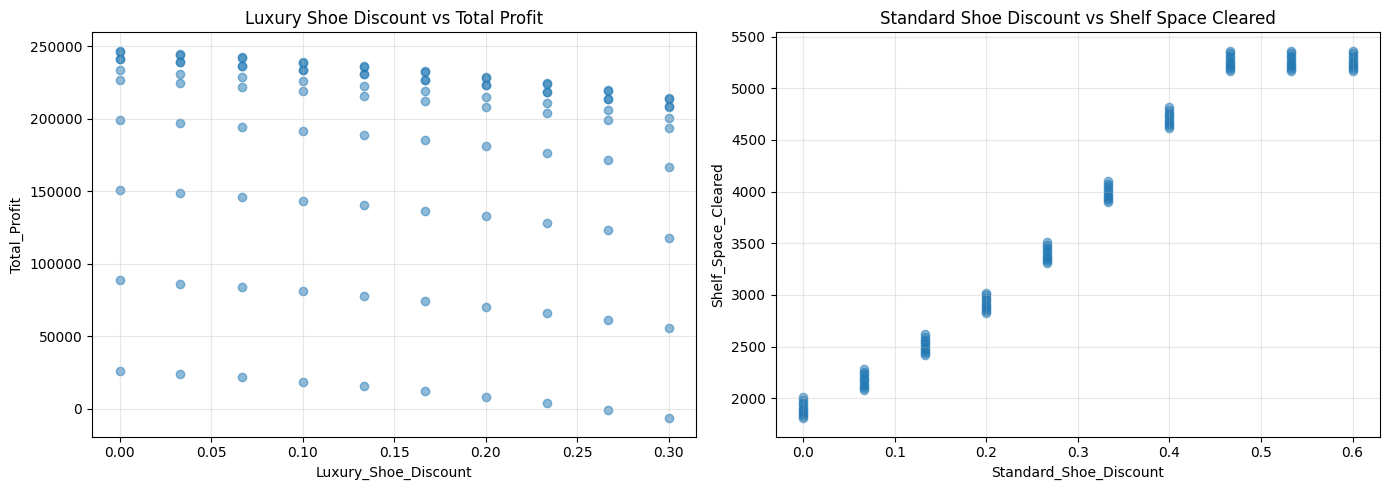

In [32]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: How decision variables affect objective 1
axes[0].scatter(df['Luxury_Shoe_Discount'], df['Total_Profit'], alpha=0.5)
axes[0].set_xlabel('Luxury_Shoe_Discount')
axes[0].set_ylabel('Total_Profit')
axes[0].set_title('Luxury Shoe Discount vs Total Profit')
axes[0].grid(True, alpha=0.3)

# YOUR CODE HERE: Create second plot for objective 2
axes[1].scatter(df['Standard_Shoe_Discount'], df['Shelf_Space_Cleared'], alpha=0.5)
axes[1].set_xlabel('Standard_Shoe_Discount')
axes[1].set_ylabel('Shelf_Space_Cleared')
axes[1].set_title('Standard Shoe Discount vs Shelf Space Cleared')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
#fix once in git
plt.savefig('data_exploration.png', dpi=300, bbox_inches='tight')
plt.show()


As can be seen in the graphs the ranges of the discounts are realistic as when the discount of the luxury show increases the profits decrease as the system loses money but when the discount increases, there is more shelf space that was cleared as more people bought the discounted shoes. The graphs have multiple points for each X value since total profit and space cleared are affected by both luxury and standard shoe discounts. In order to show both at the same time we would need a graph of dimensions higher than 2D in order to see both. With this in mind there are no data issues that can be seen at the moment.

Section 3: Pareto Frontier Calculation


In [33]:
def is_pareto_optimal(idx, df, obj1_col, obj2_col):
    """
    Check if a given row represents a Pareto optimal solution.

    A point is Pareto optimal if no other point dominates it.
    Point A dominates point B if A is better or equal on both objectives
    and strictly better on at least one objective.

    Parameters:
    -----------
    idx : int
        Index of the row to check
    df : DataFrame
        The full dataset
    obj1_col : str
        Column name for objective 1
    obj2_col : str
        Column name for objective 2

    Returns:
    --------
    bool : True if Pareto optimal, False if dominated
    """
    current_obj1 = df.loc[idx, obj1_col]
    current_obj2 = df.loc[idx, obj2_col]

    # Check if any other point dominates this one
    for other_idx in df.index:
        if other_idx == idx:
            continue

        other_obj1 = df.loc[other_idx, obj1_col]
        other_obj2 = df.loc[other_idx, obj2_col]

        # YOUR CODE HERE: Check if other point dominates current point
        # (other is >= on both objectives AND > on at least one)
        if (other_obj1 >= current_obj1 and
            other_obj2 >= current_obj2 and
            (other_obj1 > current_obj1 or other_obj2 > current_obj2)):
            return False  # This point is dominated

    return True  # No point dominates this one


In [34]:
# Define your objective column names
OBJECTIVE_1 = 'norm_Profit'  # e.g., 'driver_satisfaction'
OBJECTIVE_2 = 'norm_Space'  # e.g., 'rider_satisfaction'

print("Calculating Pareto frontier...")
print("This may take a moment for large datasets...")

# Apply Pareto check to all rows
df['is_pareto_optimal'] = df.index.map(
    lambda idx: is_pareto_optimal(idx, df, OBJECTIVE_1, OBJECTIVE_2)
)

# Separate into frontier and dominated points
pareto_df = df[df['is_pareto_optimal']].copy()
dominated_df = df[~df['is_pareto_optimal']].copy()

print("\n=== PARETO FRONTIER RESULTS ===")
print(f"Total solutions analyzed: {len(df)}")
print(f"Pareto optimal solutions: {len(pareto_df)}")
print(f"Dominated solutions: {len(dominated_df)}")
print(f"Efficiency rate: {100 * len(pareto_df) / len(df):.1f}% of solutions are on the frontier")


Calculating Pareto frontier...
This may take a moment for large datasets...

=== PARETO FRONTIER RESULTS ===
Total solutions analyzed: 100
Pareto optimal solutions: 37
Dominated solutions: 63
Efficiency rate: 37.0% of solutions are on the frontier


The percentage of effiecent solutions in this dataset is 37%. This shows that there is many ineffecient solutions and helps to show just how hard this problem has been to solve for Foot-Locker.

Ineffeicent solutions analysis:


In [35]:
if len(dominated_df) > 0:
    print("=== EXAMPLES OF DOMINATED (INEFFICIENT) SOLUTIONS ===\n")

    # Sample a few dominated points
    sample_size = min(3, len(dominated_df))
    sample_dominated = dominated_df.sample(sample_size, random_state=42)

    for idx, row in sample_dominated.iterrows():
        print(f"INEFFICIENT SOLUTION:")
        print(f"  Decision Variables: {row['Luxury_Shoe_Discount']}, {row['Standard_Shoe_Discount']}")
        print(f"  Objectives: {OBJECTIVE_1}={row[OBJECTIVE_1]:.1f}, {OBJECTIVE_2}={row[OBJECTIVE_2]:.1f}")

        # YOUR CODE HERE: Find a Pareto point that dominates this one
        for p_idx, p_row in pareto_df.iterrows():
            if (p_row[OBJECTIVE_1] >= row[OBJECTIVE_1] and
                p_row[OBJECTIVE_2] >= row[OBJECTIVE_2] and
                (p_row[OBJECTIVE_1] > row[OBJECTIVE_1] or
                 p_row[OBJECTIVE_2] > row[OBJECTIVE_2])):

                print(f"\n  BETTER ALTERNATIVE (Pareto Optimal):")
                print(f"  Decision Variables: {p_row['Luxury_Shoe_Discount']}, {p_row['Standard_Shoe_Discount']}")
                print(f"  Objectives: {OBJECTIVE_1}={p_row[OBJECTIVE_1]:.1f}, {OBJECTIVE_2}={p_row[OBJECTIVE_2]:.1f}")
                print(f"  Improvement: +{p_row[OBJECTIVE_1] - row[OBJECTIVE_1]:.1f} on {OBJECTIVE_1}, " +
                      f"+{p_row[OBJECTIVE_2] - row[OBJECTIVE_2]:.1f} on {OBJECTIVE_2}\n")
                print("-" * 60)
                break
else:
    print("Note: All solutions in your dataset are Pareto optimal.")
    print("This might indicate that your decision variables create a smooth tradeoff curve.")


=== EXAMPLES OF DOMINATED (INEFFICIENT) SOLUTIONS ===

INEFFICIENT SOLUTION:
  Decision Variables: 0.3, 0.5333
  Objectives: norm_Profit=0.2, norm_Space=1.0

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: 0.3, 0.4667
  Objectives: norm_Profit=0.5, norm_Space=1.0
  Improvement: +0.2 on norm_Profit, +0.0 on norm_Space

------------------------------------------------------------
INEFFICIENT SOLUTION:
  Decision Variables: 0.3, 0.1333
  Objectives: norm_Profit=0.9, norm_Space=0.2

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: 0.0, 0.2
  Objectives: norm_Profit=1.0, norm_Space=0.3
  Improvement: +0.1 on norm_Profit, +0.1 on norm_Space

------------------------------------------------------------
INEFFICIENT SOLUTION:
  Decision Variables: 0.0, 0.0
  Objectives: norm_Profit=0.9, norm_Space=0.0

  BETTER ALTERNATIVE (Pareto Optimal):
  Decision Variables: 0.0, 0.2
  Objectives: norm_Profit=1.0, norm_Space=0.3
  Improvement: +0.1 on norm_Profit, +0.3 on norm_Space

In [36]:
# Compare best dominated point to worst Pareto point
if len(dominated_df) > 0:
  best_dominated = dominated_df.loc[
(dominated_df[OBJECTIVE_1] + dominated_df[OBJECTIVE_2]).idxmax()
]
  worst_pareto = pareto_df.loc[
(pareto_df[OBJECTIVE_1] + pareto_df[OBJECTIVE_2]).idxmin()
]

print("\n=== EFFICIENCY GAP ===")
# This was commented out as it was false, thats not how it works print("Even the BEST dominated solution is worse than the WORST Pareto solution:")
print(f"\nBest Dominated: {OBJECTIVE_1}={best_dominated[OBJECTIVE_1]:.1f}, " +
      f"{OBJECTIVE_2}={best_dominated[OBJECTIVE_2]:.1f}, Total={best_dominated[OBJECTIVE_1] + best_dominated[OBJECTIVE_2]:.1f}")
print(f"Worst Pareto: {OBJECTIVE_1}={worst_pareto[OBJECTIVE_1]:.1f}, " +
      f"{OBJECTIVE_2}={worst_pareto[OBJECTIVE_2]:.1f}, Total={worst_pareto[OBJECTIVE_1] + worst_pareto[OBJECTIVE_2]:.1f}")



=== EFFICIENCY GAP ===

Best Dominated: norm_Profit=0.8, norm_Space=0.6, Total=1.4
Worst Pareto: norm_Profit=1.0, norm_Space=0.3, Total=1.3


It may look like the Dominated point is better than the Pareto but this would be a conclusion drawn from a fundemental misunderstanding of a pareto point. The best dominated point is a balance between profit and space but there are Pareto points that are better than it. The so called worse Pareto still maximizes one of the two objectives and does it well.

Section 4: Strategic Analysis

In [37]:
print("=== KEY STRATEGIC POINTS ON THE PARETO FRONTIER ===\n")

# Strategy 1: Balanced (Maximize total value)
pareto_df['total_objective'] = pareto_df[OBJECTIVE_1] + pareto_df[OBJECTIVE_2]
balanced_idx = pareto_df['total_objective'].idxmax()

print("1. BALANCED STRATEGY (Maximize combined objectives)")
print(f"   Decision Variables: {pareto_df.loc[balanced_idx, 'Luxury_Shoe_Discount']}, {pareto_df.loc[balanced_idx, 'Standard_Shoe_Discount']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[balanced_idx, OBJECTIVE_1]:.1f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[balanced_idx, OBJECTIVE_2]:.1f}")
print(f"   Total: {pareto_df.loc[balanced_idx, 'total_objective']:.1f}\n")

# Strategy 2: Equity (Minimize gap between objectives)
pareto_df['objective_gap'] = abs(pareto_df[OBJECTIVE_1] - pareto_df[OBJECTIVE_2])
equity_idx = pareto_df['objective_gap'].idxmin()

# YOUR CODE HERE: Print the equity strategy details
print("2. EQUITY STRATEGY (Most equal outcomes)")
print(f"   Decision Variables: {pareto_df.loc[balanced_idx, 'Luxury_Shoe_Discount']}, {pareto_df.loc[balanced_idx, 'Standard_Shoe_Discount']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[balanced_idx, OBJECTIVE_1]:.1f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[balanced_idx, OBJECTIVE_2]:.1f}")
print(f"   Gap: {pareto_df.loc[equity_idx, 'objective_gap']:.1f}\n")

# Strategy 3: Objective 1 Priority (Maximize first objective)
obj1_priority_idx = pareto_df[OBJECTIVE_1].idxmax()

print("3. OBJECTIVE 1 PRIORITY (Maximize first stakeholder)")
print(f"   Decision Variables: {pareto_df.loc[obj1_priority_idx, 'Luxury_Shoe_Discount']}, {pareto_df.loc[obj1_priority_idx, 'Standard_Shoe_Discount']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[obj1_priority_idx, OBJECTIVE_1]:.1f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[obj1_priority_idx, OBJECTIVE_2]:.1f}\n")

# Strategy 4: Objective 2 Priority (Maximize second objective)
obj2_priority_idx = pareto_df[OBJECTIVE_2].idxmax()

print("4. OBJECTIVE 2 PRIORITY (Maximize second stakeholder)")
print(f"   Decision Variables: {pareto_df.loc[obj2_priority_idx, 'Luxury_Shoe_Discount']}, {pareto_df.loc[obj2_priority_idx, 'Standard_Shoe_Discount']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[obj2_priority_idx, OBJECTIVE_1]:.1f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[obj2_priority_idx, OBJECTIVE_2]:.1f}\n")

# Strategy 5: Custom weighted (e.g., 60/40 split)
pareto_df['weighted_objective'] = (0.6 * pareto_df[OBJECTIVE_1] +
                                   0.4 * pareto_df[OBJECTIVE_2])
weighted_idx = pareto_df['weighted_objective'].idxmax()

print("5. WEIGHTED STRATEGY (60% objective 1, 40% objective 2)")
print(f"   Decision Variables: {pareto_df.loc[weighted_idx, 'Luxury_Shoe_Discount']}, {pareto_df.loc[weighted_idx, 'Standard_Shoe_Discount']}")
print(f"   {OBJECTIVE_1}: {pareto_df.loc[weighted_idx, OBJECTIVE_1]:.1f}")
print(f"   {OBJECTIVE_2}: {pareto_df.loc[weighted_idx, OBJECTIVE_2]:.1f}")


=== KEY STRATEGIC POINTS ON THE PARETO FRONTIER ===

1. BALANCED STRATEGY (Maximize combined objectives)
   Decision Variables: 0.0, 0.4
   norm_Profit: 0.8
   norm_Space: 0.8
   Total: 1.6

2. EQUITY STRATEGY (Most equal outcomes)
   Decision Variables: 0.0, 0.4
   norm_Profit: 0.8
   norm_Space: 0.8
   Gap: 0.0

3. OBJECTIVE 1 PRIORITY (Maximize first stakeholder)
   Decision Variables: 0.0, 0.2
   norm_Profit: 1.0
   norm_Space: 0.3

4. OBJECTIVE 2 PRIORITY (Maximize second stakeholder)
   Decision Variables: 0.3, 0.4667
   norm_Profit: 0.5
   norm_Space: 1.0

5. WEIGHTED STRATEGY (60% objective 1, 40% objective 2)
   Decision Variables: 0.0, 0.4
   norm_Profit: 0.8
   norm_Space: 0.8


In [39]:
# Build comparison dataframe
strategies = {
    'Strategy': [
        'Objective 1 Priority',
        'Weighted (60/40)',
        'Balanced',
        'Equity',
        'Objective 2 Priority'
    ],
    'Decision Var 1': [
        pareto_df.loc[obj1_priority_idx, 'Luxury_Shoe_Discount'],
        pareto_df.loc[weighted_idx, 'Luxury_Shoe_Discount'],
        pareto_df.loc[balanced_idx, 'Luxury_Shoe_Discount'],
        pareto_df.loc[equity_idx, 'Luxury_Shoe_Discount'],
        pareto_df.loc[obj2_priority_idx, 'Luxury_Shoe_Discount']
    ],
    'Decision Var 2': [
        pareto_df.loc[obj1_priority_idx, 'Standard_Shoe_Discount'],
        pareto_df.loc[weighted_idx, 'Standard_Shoe_Discount'],
        pareto_df.loc[balanced_idx, 'Standard_Shoe_Discount'],
        pareto_df.loc[equity_idx, 'Standard_Shoe_Discount'],
        pareto_df.loc[obj2_priority_idx, 'Standard_Shoe_Discount']
    ],
    OBJECTIVE_1: [
        f"{pareto_df.loc[obj1_priority_idx, OBJECTIVE_1]:.1f}",
        f"{pareto_df.loc[weighted_idx, OBJECTIVE_1]:.1f}",
        f"{pareto_df.loc[balanced_idx, OBJECTIVE_1]:.1f}",
        f"{pareto_df.loc[equity_idx, OBJECTIVE_1]:.1f}",
        f"{pareto_df.loc[obj2_priority_idx, OBJECTIVE_1]:.1f}"
    ],
    OBJECTIVE_2: [
        f"{pareto_df.loc[obj1_priority_idx, OBJECTIVE_2]:.1f}",
        f"{pareto_df.loc[weighted_idx, OBJECTIVE_2]:.1f}",
        f"{pareto_df.loc[balanced_idx, OBJECTIVE_2]:.1f}",
        f"{pareto_df.loc[equity_idx, OBJECTIVE_2]:.1f}",
        f"{pareto_df.loc[obj2_priority_idx, OBJECTIVE_2]:.1f}"
    ]
}

comparison_df = pd.DataFrame(strategies)

print("\n" + "="*80)
print("STRATEGIC OPTIONS COMPARISON")
print("="*80)
print(comparison_df.to_string(index=False))
print("="*80)



STRATEGIC OPTIONS COMPARISON
            Strategy  Decision Var 1  Decision Var 2 norm_Profit norm_Space
Objective 1 Priority          0.0000          0.2000         1.0        0.3
    Weighted (60/40)          0.0000          0.4000         0.8        0.8
            Balanced          0.0000          0.4000         0.8        0.8
              Equity          0.0667          0.4000         0.8        0.8
Objective 2 Priority          0.3000          0.4667         0.5        1.0


Section 5: Visualization

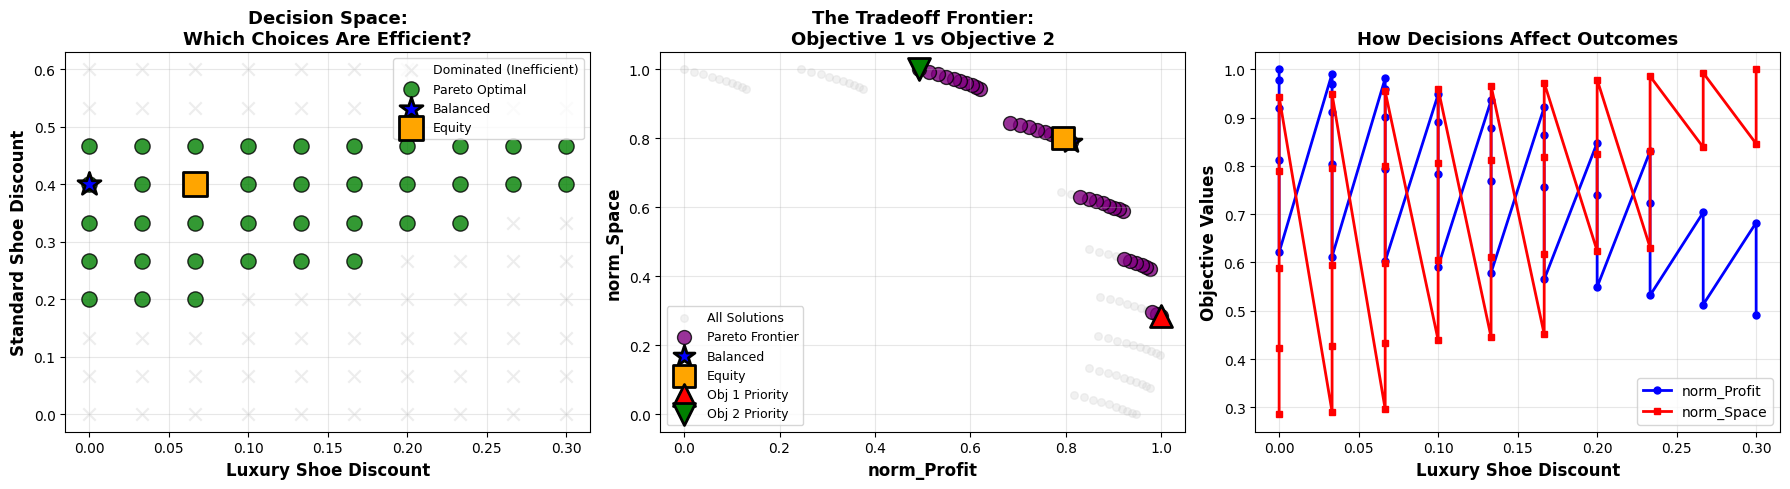


✓ Visualization saved as 'images/pareto_frontier_analysis.png'


In [42]:
import numpy as np

# Create figure with three subplots
fig = plt.figure(figsize=(18, 5))

# PANEL 1: Decision Space (show which variable combinations are efficient)
ax1 = fig.add_subplot(131)

# Plot dominated points
if len(dominated_df) > 0:
    ax1.scatter(dominated_df['Luxury_Shoe_Discount'], dominated_df['Standard_Shoe_Discount'],
               s=80, c='lightgray', alpha=0.4, marker='x',
               label='Dominated (Inefficient)', zorder=1)

# Plot Pareto optimal points
ax1.scatter(pareto_df['Luxury_Shoe_Discount'], pareto_df['Standard_Shoe_Discount'],
           s=120, c='green', alpha=0.8, marker='o',
           edgecolors='black', linewidth=1,
           label='Pareto Optimal', zorder=2)

# Highlight key strategies
ax1.scatter(pareto_df.loc[balanced_idx, 'Luxury_Shoe_Discount'],
           pareto_df.loc[balanced_idx, 'Standard_Shoe_Discount'],
           s=300, c='blue', marker='*',
           edgecolors='black', linewidth=2,
           label='Balanced', zorder=3)

# YOUR CODE HERE: Add equity strategy point
ax1.scatter(pareto_df.loc[equity_idx, 'Luxury_Shoe_Discount'],
           pareto_df.loc[equity_idx, 'Standard_Shoe_Discount'],
           s=300, c='orange', marker='s',
           edgecolors='black', linewidth=2,
           label='Equity', zorder=3)

ax1.set_xlabel('Luxury Shoe Discount', fontsize=12, fontweight='bold')
ax1.set_ylabel('Standard Shoe Discount', fontsize=12, fontweight='bold')
ax1.set_title('Decision Space:\nWhich Choices Are Efficient?',
              fontsize=13, fontweight='bold')
ax1.legend(fontsize=9, loc='best')
ax1.grid(True, alpha=0.3)

# PANEL 2: Objective Space (the Pareto frontier)
ax2 = fig.add_subplot(132)

# Plot all points
ax2.scatter(df[OBJECTIVE_1], df[OBJECTIVE_2],
           s=30, c='lightgray', alpha=0.3,
           label='All Solutions')

# Plot Pareto frontier
ax2.scatter(pareto_df[OBJECTIVE_1], pareto_df[OBJECTIVE_2],
           s=100, c='purple', alpha=0.8,
           edgecolors='black', linewidth=1,
           label='Pareto Frontier')

# Highlight strategies
strategies_to_plot = [
    (balanced_idx, 'blue', '*', 'Balanced'),
    (equity_idx, 'orange', 's', 'Equity'),
    (obj1_priority_idx, 'red', '^', 'Obj 1 Priority'),
    (obj2_priority_idx, 'green', 'v', 'Obj 2 Priority')
]

for idx, color, marker, label in strategies_to_plot:
    ax2.scatter(pareto_df.loc[idx, OBJECTIVE_1],
               pareto_df.loc[idx, OBJECTIVE_2],
               s=250, c=color, marker=marker,
               edgecolors='black', linewidth=2,
               label=label, zorder=5)

ax2.set_xlabel(f'{OBJECTIVE_1}', fontsize=12, fontweight='bold')
ax2.set_ylabel(f'{OBJECTIVE_2}', fontsize=12, fontweight='bold')
ax2.set_title('The Tradeoff Frontier:\n Total Profit vs Space Cleared',
              fontsize=13, fontweight='bold')
ax2.legend(fontsize=9, loc='best')
ax2.grid(True, alpha=0.3)

# PANEL 3: Tradeoff Curve (both objectives vs one decision variable)
ax3 = fig.add_subplot(133)

# Sort by first decision variable for cleaner line plots
pareto_sorted = pareto_df.sort_values('Luxury_Shoe_Discount')

# YOUR CODE HERE: Plot both objectives against the primary decision variable
ax3.plot(pareto_sorted['Luxury_Shoe_Discount'], pareto_sorted[OBJECTIVE_1],
        'b-o', linewidth=2, markersize=5, label=OBJECTIVE_1)
ax3.plot(pareto_sorted['Luxury_Shoe_Discount'], pareto_sorted[OBJECTIVE_2],
        'r-s', linewidth=2, markersize=5, label=OBJECTIVE_2)

ax3.set_xlabel('Luxury Shoe Discount', fontsize=12, fontweight='bold')
ax3.set_ylabel('Objective Values', fontsize=12, fontweight='bold')
ax3.set_title('How Decisions Affect Outcomes',
              fontsize=13, fontweight='bold')
ax3.legend(fontsize=10, loc='best')
ax3.grid(True, alpha=0.3)

plt.tight_layout()
#fix once in github
plt.savefig('pareto_frontier_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Visualization saved as 'images/pareto_frontier_analysis.png'")


The first panel shows all the different combinations of discounts that can equal a pareto optimal solution. This shows the actual discounts that we would need to implement to achieve our goal. The 2nd panel goes over the actual objectives that in relatetion to those pareto points. This shows how those pareto points actually affect our two objectives. Finally the third panel shows how much impact the Luxury Shoe discounts have on the actual objectives. There isn't much effect until the percent is 20% or higher.

Section 6: Summary and Insights


What You Found:

We found that there were 37 possible pareto optimal points. The best for profit was having a 20% discount for regular shoes which maximized profit while still saving some space. Space was maximized by increasing luxury discount to 30% and setting the regular shoes at 47%. The best option that balances out both is to only have a 40% discount on regular shoes getting 80% max profit and 80% max space.

Business Implications:

This reveals how the profit vs space decision variables of discounts are more level based. In other words discounts need to reach a certain threshold for them to matter. This is why some discounts are useless in effect such as only a 10% discount on regular shoes no matter how much it affects the luxury shoes. There are some points that have different strategies like 20% regular shoes maximizes profit where as a 40% discount balances the two objectives better. What strategy is better can be determined by the position of foot locker and how quickly they are selling stock.

Limitations:

This model does have a few limitations, such as the fact that it uses synthetic data, which means that while the data is neat it might not be as accurate as we could hope for. There is also the factor that we simplified the types of shoes by using luxury and regular shoes to represent a vast array of brands and varieties. We are unable to capture the exact shoes that sneaker-heads are hyped about in this data and cannot analyze that in our data. This analysis could be improved by other normalization techniques as our data at the moment is quite restricted by it, making it harder to tell the exact affects that the variables are having.  
